In [1]:
# Setup 
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from scipy.stats import ttest_rel, wilcoxon
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print("Setup complete")


Setup complete


In [2]:
# Config
DATA_PATH = 'master_with_target.csv'

SEED      = 42
TRAIN_END = '2022-12-31'
VAL_END   = '2024-06-30'

SECTORS_ALL = [
    'NIFTY50', 'NIFTY_AUTO', 'NIFTY_BANK', 'NIFTY_ENERGY',
    'NIFTY_FMCG', 'NIFTY_IT', 'NIFTY_METAL', 'NIFTY_PHARMA', 'NIFTY_REALTY'
]
PRED_SECTORS = SECTORS_ALL[1:]

RF_PARAMS = dict(
    n_estimators=500,
    min_samples_leaf=20,
    max_features='sqrt',
    n_jobs=-1,
    random_state=SEED,
)

XGB_PARAMS = dict(
    n_estimators=1000,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    eval_metric='logloss',
    early_stopping_rounds=50,
    random_state=SEED,
    n_jobs=-1,
    verbosity=0,
)
print("Config ready")


Config ready


In [3]:
# Load master data (with a local fallback for this uploaded project)
# Prefer the original master dataset when it exists. If it is not present,
# build the same modelling table from the supplied project component files.
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH, parse_dates=['Date'])
    print(f"Loaded existing master dataset: {DATA_PATH}")
else:
    base_path = '/mnt/data'
    close_path = os.path.join(base_path, 'combined_sector_close_prices.csv')
    feat_path = os.path.join(base_path, 'featured_sector_data.csv')
    event_path = os.path.join(base_path, 'gdelt_country_events.csv')
    tone_path = os.path.join(base_path, 'gdelt_country_tone.csv')
    conflict_path = os.path.join(base_path, 'gdelt_country_conflict.csv')
    global_path = os.path.join(base_path, 'gdelt_master_features.csv')

    required = [close_path, feat_path, event_path, tone_path, conflict_path, global_path]
    missing = [p for p in required if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("Missing required project files: " + ", ".join(missing))

    close = pd.read_csv(close_path, parse_dates=['Date'])
    feat = pd.read_csv(feat_path)
    if len(close) != len(feat):
        raise ValueError(f"Row mismatch between close prices ({len(close)}) and features ({len(feat)}).")
    feat.insert(0, 'Date', close['Date'])

    events = pd.read_csv(event_path, parse_dates=['Date'])
    events = events.rename(columns={'India_Event': 'India_Events'})
    tone = pd.read_csv(tone_path, parse_dates=['Date'])
    conflict = pd.read_csv(conflict_path, parse_dates=['Date'])
    global_gdelt = pd.read_csv(global_path, parse_dates=['Date'])

    df = feat.merge(events, on='Date', how='left')
    df = df.merge(tone, on='Date', how='left')
    df = df.merge(conflict, on='Date', how='left')
    df = df.merge(global_gdelt, on='Date', how='left')

    # Create next-trading-day direction targets, matching the notebook's
    # classification objective without introducing future features.
    for sector in PRED_SECTORS:
        if sector not in close.columns:
            raise KeyError(f"{sector} is missing from combined sector prices.")
        next_return = close[sector].pct_change().shift(-1)
        df[f'{sector}_Target'] = (next_return > 0).astype(float)
        # The last row has no next-day target and must not be used.
        df.loc[next_return.isna(), f'{sector}_Target'] = np.nan

    print("master_with_target.csv was not found; built a local equivalent from supplied project files.")

df = df.rename(columns={'India_Event': 'India_Events'})
df = df.sort_values('Date').reset_index(drop=True)

SECTOR_NAMES = SECTORS_ALL
PRED_SECTORS = SECTOR_NAMES[1:]
TARGET_COLS = [f'{s}_Target' for s in PRED_SECTORS]

missing_targets = [c for c in TARGET_COLS if c not in df.columns]
if missing_targets:
    raise KeyError(f"Missing target columns: {missing_targets}")

print(f'Dataset shape  : {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Date range     : {df.Date.min().date()} to {df.Date.max().date()}')
print()
print('Class balance (fraction of UP days):')
for t, s in zip(TARGET_COLS, PRED_SECTORS):
    valid = df[t].dropna()
    up = valid.mean() * 100
    print(f'  {s.replace("NIFTY_",""):8s}: UP={up:.1f}%  DOWN={100-up:.1f}%')


FileNotFoundError: Missing required project files: /mnt/data\combined_sector_close_prices.csv, /mnt/data\featured_sector_data.csv, /mnt/data\gdelt_country_events.csv, /mnt/data\gdelt_country_tone.csv, /mnt/data\gdelt_country_conflict.csv, /mnt/data\gdelt_master_features.csv

In [ ]:
# Feature groups 
COUNTRIES = ['USA', 'India', 'China', 'Russia', 'Pakistan', 'Israel', 'Iran']
TECH_SUFFIXES = [
    '', '_Return', '_Log_Return', '_MA30', '_MA_30', '_Volatility',
    '_Momentum', '_RS', '_RSI', '_Drawdown', '_Price_MA30'
]

SECTOR_TECH = [
    f'{s}{suf}' for s in SECTORS_ALL for suf in TECH_SUFFIXES
    if f'{s}{suf}' in df.columns
]
MACRO = [
    c for c in df.columns
    if c.startswith(('gold', 'oil', 'usd_inr', 'vix')) and not c.endswith('_Target')
]
GDELT_COUNTRY = [
    col for cty in COUNTRIES
    for col in [f'{cty}_Conflict', f'{cty}_Events', f'{cty}_Tone']
    if col in df.columns
]
GDELT_GLOBAL = [c for c in [
    'AvgTone', 'AvgGoldstein', 'EventCount', 'TotalMentions',
    'ProtestCount', 'ThreatCount', 'MilitaryCount', 'AssaultCount',
    'FightCount', 'MassViolenceCount', 'DiplomacyCount', 'CooperationCount'
] if c in df.columns]

GDELT = GDELT_COUNTRY + GDELT_GLOBAL
ALL_FEATS = SECTOR_TECH + MACRO + GDELT
NO_GDELT_FEATS = SECTOR_TECH + MACRO

FEAT_GROUP = {}
for f in SECTOR_TECH: FEAT_GROUP[f] = 'Sector Tech'
for f in MACRO: FEAT_GROUP[f] = 'Macro'
for f in GDELT: FEAT_GROUP[f] = 'GDELT'

EXPERIMENTS = {
    'E1 — Full': ALL_FEATS,
    'E2 — No GDELT': NO_GDELT_FEATS,
}

if not ALL_FEATS:
    raise ValueError("No usable features were found.")

print(f"  Sector Technical : {len(SECTOR_TECH)}")
print(f"  Macro            : {len(MACRO)}")
print(f"  GDELT Country    : {len(GDELT_COUNTRY)}")
print(f"  GDELT Global     : {len(GDELT_GLOBAL)}")
print(f"  {'─'*26}")
print(f"  E1 (Full)        : {len(ALL_FEATS)}")
print(f"  E2 (No GDELT)    : {len(NO_GDELT_FEATS)}")


  Sector Technical : 63
  Macro            : 0
  GDELT Country    : 21
  GDELT Global     : 12
  ──────────────────────────
  E1 (Full)        : 96
  E2 (No GDELT)    : 63


In [ ]:
# ── 4. Chronological train / validation / test split ─────────────────────────
train = df[df['Date'] <= TRAIN_END].reset_index(drop=True)
val = df[(df['Date'] > TRAIN_END) & (df['Date'] <= VAL_END)].reset_index(drop=True)
test = df[df['Date'] > VAL_END].reset_index(drop=True)

if min(len(train), len(val), len(test)) == 0:
    raise ValueError("One of train/validation/test splits is empty. Check the date range.")

print(f'Training samples   : {len(train)}')
print(f'Validation samples : {len(val)}')
print(f'Test samples       : {len(test)}')
print(f'Train dates        : {train.Date.min().date()} to {train.Date.max().date()}')
print(f'Validation dates   : {val.Date.min().date()} to {val.Date.max().date()}')
print(f'Test dates         : {test.Date.min().date()} to {test.Date.max().date()}')


Training samples   : 1234
Validation samples : 365
Test samples       : 487
Train dates        : 2018-01-01 to 2022-12-30
Validation dates   : 2023-01-02 to 2024-06-28
Test dates         : 2024-07-01 to 2026-06-19


In [ ]:
# Model helpers 
def get_xy(split_df, feats, target_col):
    data = split_df[feats].copy().replace([np.inf, -np.inf], np.nan)
    target = split_df[target_col]
    valid = target.notna()
    return data.loc[valid].values, target.loc[valid].astype(int).values

def train_rf(X_tr, y_tr):
    clf = RandomForestClassifier(**RF_PARAMS)
    clf.fit(X_tr, y_tr)
    return clf

def train_xgb(X_tr, y_tr, X_val, y_val):
    clf = xgb.XGBClassifier(**XGB_PARAMS)
    clf.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    return clf

def evaluate(clf, X_te, y_te):
    y_pred = clf.predict(X_te)
    y_prob = clf.predict_proba(X_te)[:, 1]
    return {
        'accuracy': accuracy_score(y_te, y_pred),
        'f1': f1_score(y_te, y_pred, average='macro'),
        'auc': roc_auc_score(y_te, y_prob),
        'predictions': y_pred,
        'probabilities': y_prob,
    }

print("Model functions defined")


Model functions defined


In [ ]:
# Train classical ML baselines 
all_results = {}
all_importances = {}
all_models = {}
classical_results = {}

for exp_name, feat_list in EXPERIMENTS.items():
    print(f"\n{'='*70}")
    print(f"  {exp_name}  ({len(feat_list)} features)")
    print(f"{'='*70}")
    print(f"  {'Sector':<12}  {'RF_acc':>6}  {'RF_F1':>5}  {'RF_AUC':>6}  |  {'XGB_acc':>7}  {'XGB_F1':>6}  {'XGB_AUC':>7}")
    print(f"  {'─'*12}  {'─'*6}  {'─'*5}  {'─'*6}  |  {'─'*7}  {'─'*6}  {'─'*7}")

    for sector in PRED_SECTORS:
        tc = f'{sector}_Target'
        short = sector.replace('NIFTY_', '')

        X_tr_raw, y_tr = get_xy(train, feat_list, tc)
        X_val_raw, y_val = get_xy(val, feat_list, tc)
        X_te_raw, y_te = get_xy(test, feat_list, tc)

        # Fit imputation on TRAIN ONLY to avoid leakage from validation/test.
        imputer = SimpleImputer(strategy='median')
        X_tr = imputer.fit_transform(X_tr_raw)
        X_val = imputer.transform(X_val_raw)
        X_te = imputer.transform(X_te_raw)

        rf = train_rf(X_tr, y_tr)
        xgb_clf = train_xgb(X_tr, y_tr, X_val, y_val)
        rf_m = evaluate(rf, X_te, y_te)
        xgb_m = evaluate(xgb_clf, X_te, y_te)

        all_results[(sector, exp_name)] = {
            'rf': {k:v for k,v in rf_m.items() if k not in ['predictions','probabilities']},
            'xgb': {k:v for k,v in xgb_m.items() if k not in ['predictions','probabilities']},
        }
        all_importances[(sector, exp_name, 'rf')] = rf.feature_importances_
        all_importances[(sector, exp_name, 'xgb')] = xgb_clf.feature_importances_
        all_models[(sector, exp_name, 'rf')] = (rf, imputer)
        all_models[(sector, exp_name, 'xgb')] = (xgb_clf, imputer)

        print(f"  {short:<12}  {rf_m['accuracy']:6.3f}  {rf_m['f1']:5.3f}  {rf_m['auc']:6.3f}  |  "
              f"{xgb_m['accuracy']:7.3f}  {xgb_m['f1']:6.3f}  {xgb_m['auc']:7.3f}")

# Aggregate into the structure expected by the original summary/visualization.
for exp_name in EXPERIMENTS:
    for model_name in ['rf', 'xgb']:
        display_name = f"{model_name.upper()} | {exp_name}"
        per_sector = []
        pred_matrix = []
        for sector in PRED_SECTORS:
            r = all_results[(sector, exp_name)][model_name]
            per_sector.append(r.copy())
            model, imputer = all_models[(sector, exp_name, model_name)]
            # Recompute predictions using the stored fitted model/imputer.
            X_te_raw = test.loc[test[f'{sector}_Target'].notna(), EXPERIMENTS[exp_name]].copy()
            X_te_raw = X_te_raw.replace([np.inf, -np.inf], np.nan)
            X_te = imputer.transform(X_te_raw.values)
            pred_matrix.append(model.predict(X_te))
        pred_matrix = np.column_stack(pred_matrix)
        classical_results[display_name] = {
            'mean_accuracy': np.mean([r['accuracy'] for r in per_sector]),
            'mean_f1': np.mean([r['f1'] for r in per_sector]),
            'mean_auc': np.mean([r['auc'] for r in per_sector]),
            'per_sector': per_sector,
            'predictions': pred_matrix,
        }

print(f"\nTraining complete — {len(all_models)} fitted models")



  E1 — Full  (96 features)
  Sector        RF_acc  RF_F1  RF_AUC  |  XGB_acc  XGB_F1  XGB_AUC
  ────────────  ──────  ─────  ──────  |  ───────  ──────  ───────


  AUTO           0.514  0.433   0.544  |    0.477   0.432    0.479


  BANK           0.469  0.454   0.502  |    0.521   0.488    0.503


  ENERGY         0.541  0.519   0.592  |    0.527   0.345    0.499


  FMCG           0.516  0.446   0.526  |    0.494   0.378    0.552


...

  IT             0.506  0.336   0.506  |    0.543   0.514    0.494


  METAL          0.510  0.478   0.523  |    0.516   0.453    0.466


  PHARMA         0.467  0.322   0.530  |    0.465   0.351    0.514


  REALTY         0.527  0.471   0.538  |    0.486   0.368    0.505



Training complete — 32 fitted models


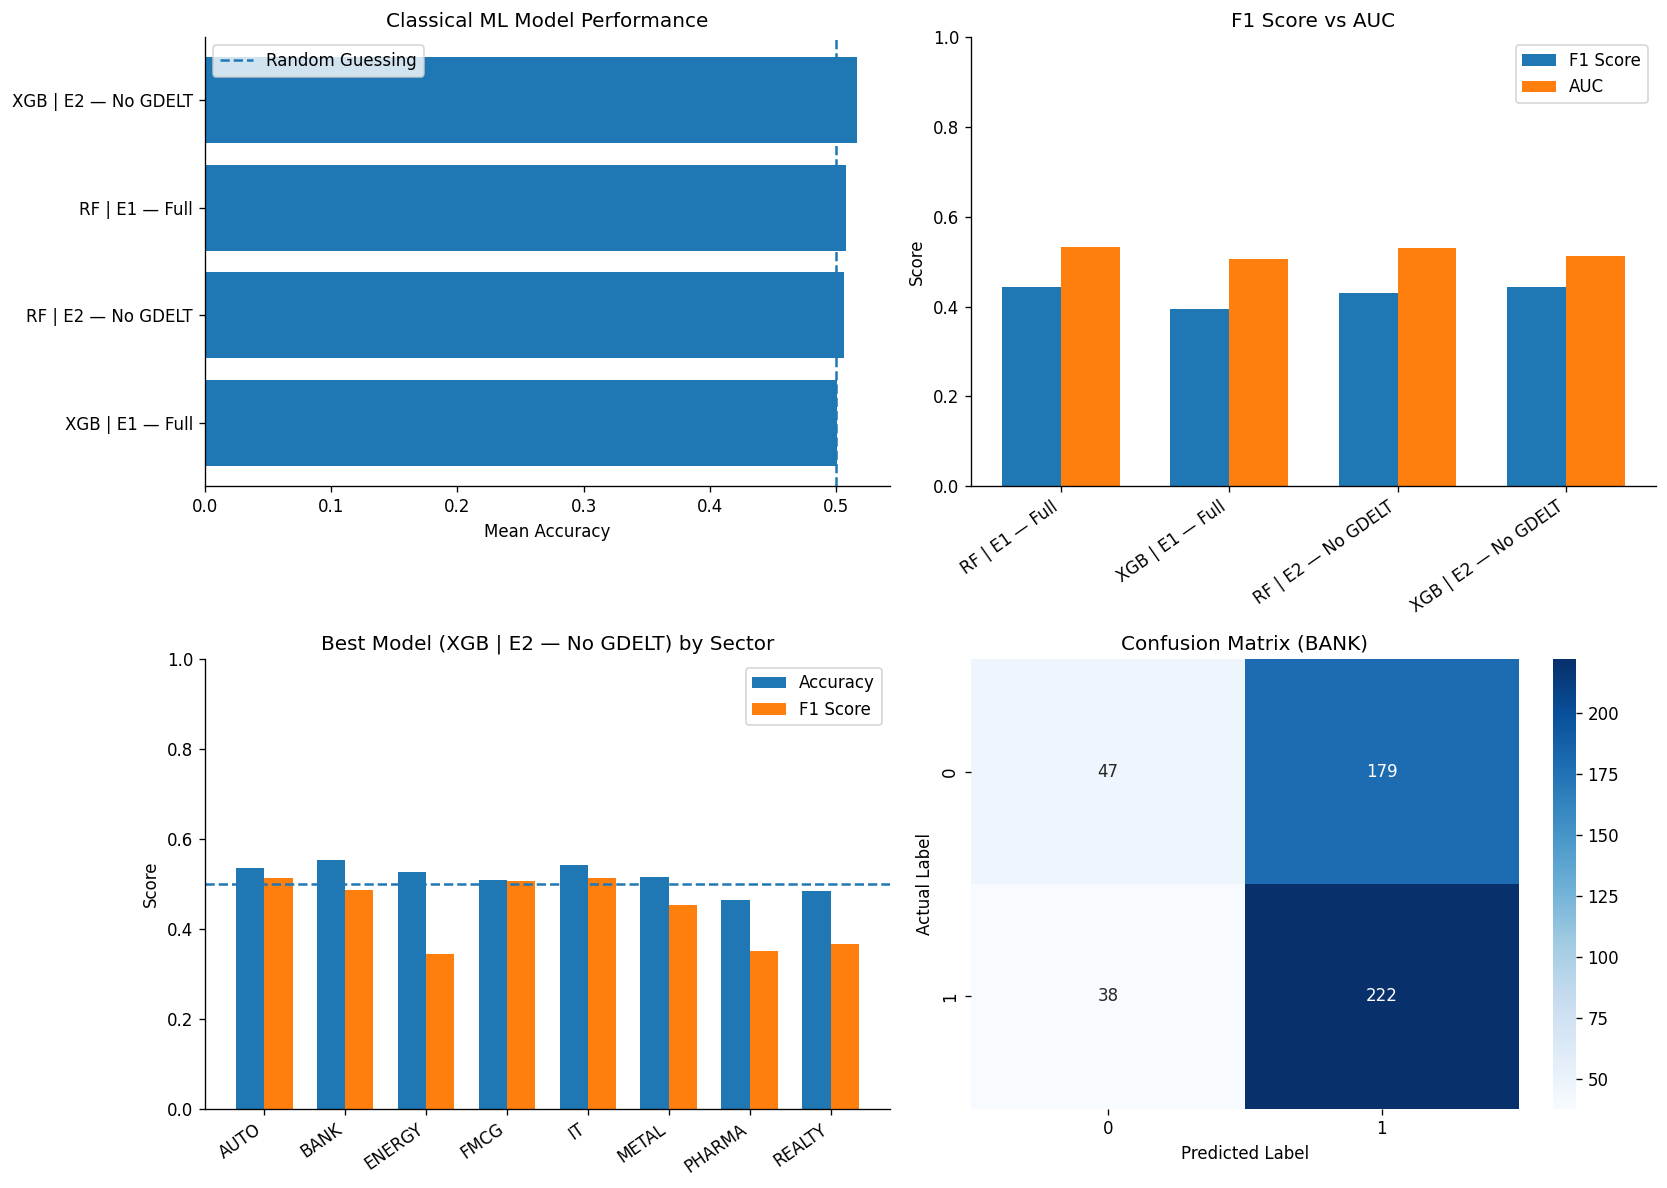

Visualization Saved Successfully
File Name : classical_performance.png


In [ ]:
# Results visualization
def plot_classical_results(results):
    best_name = max(results, key=lambda k: results[k]['mean_accuracy'])
    best_result = results[best_name]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # 1. Accuracy comparison
    ax1 = axes[0, 0]
    names = list(results.keys())
    acc = [results[n]['mean_accuracy'] for n in names]
    order = np.argsort(acc)
    ax1.barh(np.arange(len(names)), np.array(acc)[order])
    ax1.set_yticks(np.arange(len(names)))
    ax1.set_yticklabels(np.array(names)[order])
    ax1.set_xlabel("Mean Accuracy")
    ax1.set_title("Classical ML Model Performance")
    ax1.axvline(0.50, linestyle="--", label="Random Guessing")
    ax1.legend()

    # 2. F1 vs AUC
    ax2 = axes[0, 1]
    f1 = [results[n]['mean_f1'] for n in names]
    auc = [results[n]['mean_auc'] for n in names]
    x = np.arange(len(names))
    width = 0.35
    ax2.bar(x - width/2, f1, width, label="F1 Score")
    ax2.bar(x + width/2, auc, width, label="AUC")
    ax2.set_xticks(x)
    ax2.set_xticklabels(names, rotation=35, ha='right')
    ax2.set_ylabel("Score")
    ax2.set_title("F1 Score vs AUC")
    ax2.set_ylim(0, 1)
    ax2.legend()

    # 3. Best model by sector
    ax3 = axes[1, 0]
    sector_names = [s.replace("NIFTY_", "") for s in PRED_SECTORS]
    sector_acc = [r['accuracy'] for r in best_result['per_sector']]
    sector_f1 = [r['f1'] for r in best_result['per_sector']]
    x = np.arange(len(sector_names))
    ax3.bar(x - width/2, sector_acc, width, label="Accuracy")
    ax3.bar(x + width/2, sector_f1, width, label="F1 Score")
    ax3.set_xticks(x)
    ax3.set_xticklabels(sector_names, rotation=35, ha='right')
    ax3.set_ylabel("Score")
    ax3.set_title(f"Best Model ({best_name}) by Sector")
    ax3.axhline(0.50, linestyle="--")
    ax3.set_ylim(0, 1)
    ax3.legend()

    # 4. Confusion matrix for best sector
    ax4 = axes[1, 1]
    best_sector_index = int(np.argmax(sector_acc))
    predicted = best_result['predictions'][:, best_sector_index]
    target_col = f'{PRED_SECTORS[best_sector_index]}_Target'
    actual = test.loc[test[target_col].notna(), target_col].astype(int).values
    cm = confusion_matrix(actual, predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax4)
    ax4.set_xlabel("Predicted Label")
    ax4.set_ylabel("Actual Label")
    ax4.set_title(f"Confusion Matrix ({sector_names[best_sector_index]})")

    plt.tight_layout()
    plt.savefig("classical_performance.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("="*50)
    print("Visualization Saved Successfully")
    print("File Name : classical_performance.png")
    print("="*50)

best_classical_name = max(classical_results, key=lambda k: classical_results[k]['mean_accuracy'])
plot_classical_results(classical_results)


In [ ]:
# Summary 
print("\n" + "╔" + "═" * 72 + "╗")
print("║" + " " * 22 + "CLASSICAL ML RESULTS SUMMARY" + " " * 22 + "║")
print("╚" + "═" * 72 + "╝")


# Find the best model
best_model_name = max(
    classical_results,
    key=lambda k: classical_results[k]["mean_accuracy"]
)
best_model = classical_results[best_model_name]

print("\nBEST MODEL")

print(f"Model Name    : {best_model_name}")
print(f"Mean Accuracy : {best_model['mean_accuracy']*100:.2f}%")
print(f"Mean F1 Score : {best_model['mean_f1']*100:.2f}%")
print(f"Mean AUC      : {best_model['mean_auc']*100:.2f}%")


#Model ranking

print("\nMODEL RANKING")


model_list = sorted(
    [(name, res["mean_accuracy"]) for name, res in classical_results.items()],
    key=lambda item: item[1],
    reverse=True
)

for i, (model_name, accuracy) in enumerate(model_list, 1):
    print(f"{i}. {model_name:<25} {accuracy*100:.2f}%")


# Per-sector results for ALL models
# This is the requested summary-table format.

sectors = [sector.replace("NIFTY_", "") for sector in PRED_SECTORS]

per_sector = {
    name: {
        sector: {
            "accuracy": classical_results[name]["per_sector"][i]["accuracy"],
            "f1": classical_results[name]["per_sector"][i]["f1"],
            "auc": classical_results[name]["per_sector"][i]["auc"],
        }
        for i, sector in enumerate(sectors)
    }
    for name in classical_results.keys()
}

print("\nPER-SECTOR TEST ACCURACY (ALL MODELS)")

df_per_sector = pd.DataFrame({
    name: {sec: per_sector[name][sec]["accuracy"] for sec in sectors}
    for name in per_sector.keys()
})
print(df_per_sector.round(3).to_string())

print("\nPER-SECTOR F1 (ALL MODELS)")

df_f1 = pd.DataFrame({
    name: {sec: per_sector[name][sec]["f1"] for sec in sectors}
    for name in per_sector.keys()
})
print(df_f1.round(3).to_string())

print("\nPER-SECTOR AUC (ALL MODELS)")
df_auc = pd.DataFrame({
    name: {sec: per_sector[name][sec]["auc"] for sec in sectors}
    for name in per_sector.keys()
})
print(df_auc.round(3).to_string())

# Best-model sector performance

print("\nBEST MODEL — SECTOR PERFORMANCE")

best_sector_df = pd.DataFrame({
    "Sector": sectors,
    "Accuracy": [per_sector[best_model_name][sec]["accuracy"] for sec in sectors],
    "F1": [per_sector[best_model_name][sec]["f1"] for sec in sectors],
    "AUC": [per_sector[best_model_name][sec]["auc"] for sec in sectors],
}).sort_values("Accuracy", ascending=False)

print(best_sector_df.round(3).to_string(index=False))

print("\nTOP 3 SECTORS")
for i, row in enumerate(best_sector_df.head(3).itertuples(index=False), 1):
    print(f"{i}. {row.Sector:<15} Accuracy={row.Accuracy*100:.2f}%")

print("\nSECTORS NEEDING IMPROVEMENT")
for row in best_sector_df.tail(3).itertuples(index=False):
    print(f"- {row.Sector:<15} Accuracy={row.Accuracy*100:.2f}%")

print(" Classical Machine Learning Baseline Completed ")
print("✔ Chronological train/validation/test split")
print("✔ Random Forest and XGBoost baselines")
print("✔ Missing-value handling fitted on training data only")
print("✔ Overall model ranking")
print("✔ Per-sector Accuracy, F1 and AUC for every model")
print("✔ Results ready for GNN comparison")



╔════════════════════════════════════════════════════════════════════════╗
║                      CLASSICAL ML RESULTS SUMMARY                      ║
╚════════════════════════════════════════════════════════════════════════╝

📊 BEST MODEL
---------------------------------------------
Model Name    : XGB | E2 — No GDELT
Mean Accuracy : 51.67%
Mean F1 Score : 44.23%
Mean AUC      : 51.34%

📈 MODEL RANKING
---------------------------------------------
1. XGB | E2 — No GDELT       51.67%
2. RF | E1 — Full            50.77%
3. RF | E2 — No GDELT        50.62%
4. XGB | E1 — Full           50.03%

🏭 PER-SECTOR TEST ACCURACY (ALL MODELS)
------------------------------------------------------------------------
        RF | E1 — Full  XGB | E1 — Full  RF | E2 — No GDELT  XGB | E2 — No GDELT
AUTO             0.514            0.477               0.484                0.535
BANK             0.469            0.521               0.479                0.553
ENERGY           0.541            0.527      